Install

In [ ]:
!pip install gymnasium
!apt-get install -y swig
!pip install "gymnasium[box2d]"
!pip install "imageio[ffmpeg]"

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  swig-doc swig-examples
The following NEW packages will be installed:
  swig
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 1,187 kB of archives.
After this operation, 5,672 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 swig amd64 4.2.0-2ubuntu1 [1,187 kB]
Fetched 1,187 kB in 1s (818 kB/s)
Selecting previously unselected package swig.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../swig_4.2.0-2ubuntu1_amd64.deb ...
Unpacking swig (4.2.0-2ubuntu1) ...
Setting up swig (4.2.0-2ubuntu1) ...
Processing triggers for man-db (2.12.0-4build2) ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12

Imports

In [ ]:
import os, random, glob, io, base64
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque
import gymnasium as gym
import imageio
from IPython.display import HTML, display

Create the custom environment


In [ ]:
import shutil, importlib
import gymnasium.envs.box2d.lunar_lander as ll

shutil.copy(ll.__file__, 'my_lander.py')
src = open('my_lander.py').read()

# 1) Pad position comes from self.pad_center instead of the fixed middle chunk
assert "CHUNKS // 2" in src
src = src.replace("CHUNKS // 2", "self.pad_center")

# 2) Choose pad_center and compute pad_offset right after chunk_x is built
anchor = "chunk_x = [W / (CHUNKS - 1) * i for i in range(CHUNKS)]"
assert anchor in src
inject = anchor + """
        if PAD_MODE == 'right':
            self.pad_center = 7
        elif PAD_MODE == 'left':
            self.pad_center = 3
        elif PAD_MODE == 'random':
            self.pad_center = int(self.np_random.integers(2, 9))
        else:
            self.pad_center = CHUNKS // 2
        self.pad_offset = (chunk_x[self.pad_center] - W / 2) / (W / 2)
"""
src = src.replace(anchor, inject)

# 3) Reward shaping should aim at the pad, not at x = 0
old = "-100 * np.sqrt(state[0] * state[0] + state[1] * state[1])"
assert old in src
src = src.replace(old, "-100 * np.sqrt((state[0] - self.pad_offset) ** 2 + state[1] * state[1])")

# 4) Module-level setting
src = "PAD_MODE = 'right'\n" + src
open('my_lander.py', 'w').write(src)

import my_lander
importlib.reload(my_lander)

# ---- choose here: 'right', 'left', 'random', 'center' ----
my_lander.PAD_MODE = 'random'

Environment with pad position in the observation

In [ ]:
class PadObs(gym.ObservationWrapper):
    """Appends the pad's x-offset to the state so the agent knows where the pad is."""
    def __init__(self, env):
        super().__init__(env)
        low = np.append(env.observation_space.low, -1.5).astype(np.float32)
        high = np.append(env.observation_space.high, 1.5).astype(np.float32)
        self.observation_space = gym.spaces.Box(low, high, dtype=np.float32)

    def observation(self, obs):
        return np.append(obs, self.env.unwrapped.pad_offset).astype(np.float32)

def make_env(render_mode=None):
    env = my_lander.LunarLander(render_mode=render_mode)
    env = PadObs(env)
    return gym.wrappers.TimeLimit(env, max_episode_steps=1000)

env = make_env()
state_size = env.observation_space.shape[0]
number_actions = env.action_space.n
print('State size:', state_size, '| Actions:', number_actions)

State size: 9 | Actions: 4


Neural network

In [ ]:
class Network(nn.Module):
    def __init__(self, state_size, action_size, seed=42):
        super().__init__()
        self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, action_size)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

Hyperparameters, replay memory, agent

In [ ]:
learning_rate = 5e-4
minibatch_size = 100
discount_factor = 0.99
replay_buffer_size = int(1e5)
interpolation_parameter = 1e-3

class ReplayMemory:
    def __init__(self, capacity):
        self.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        self.memory = deque(maxlen=capacity)

    def push(self, event):
        self.memory.append(event)

    def sample(self, batch_size):
        exps = random.sample(self.memory, k=batch_size)
        to_t = lambda arr, dt: torch.from_numpy(np.vstack(arr).astype(dt)).to(self.device)
        states = to_t([e[0] for e in exps], np.float32)
        actions = to_t([e[1] for e in exps], np.int64)
        rewards = to_t([e[2] for e in exps], np.float32)
        next_states = to_t([e[3] for e in exps], np.float32)
        dones = to_t([e[4] for e in exps], np.float32)
        return states, next_states, actions, rewards, dones

class Agent:
    def __init__(self, state_size, action_size):
        self.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        self.action_size = action_size
        self.local_qnetwork = Network(state_size, action_size).to(self.device)
        self.target_qnetwork = Network(state_size, action_size).to(self.device)
        self.target_qnetwork.load_state_dict(self.local_qnetwork.state_dict())
        self.optimizer = optim.Adam(self.local_qnetwork.parameters(), lr=learning_rate)
        self.memory = ReplayMemory(replay_buffer_size)
        self.t_step = 0

    def step(self, state, action, reward, next_state, done):
        self.memory.push((state, action, reward, next_state, done))
        self.t_step = (self.t_step + 1) % 4
        if self.t_step == 0 and len(self.memory.memory) > minibatch_size:
            self.learn(self.memory.sample(minibatch_size), discount_factor)

    def act(self, state, epsilon=0.):
        state = torch.from_numpy(state).float().unsqueeze(0).to(self.device)
        self.local_qnetwork.eval()
        with torch.no_grad():
            action_values = self.local_qnetwork(state)
        self.local_qnetwork.train()
        if random.random() > epsilon:
            return int(np.argmax(action_values.cpu().data.numpy()))
        return random.randrange(self.action_size)

    def learn(self, experiences, discount_factor):
        states, next_states, actions, rewards, dones = experiences
        next_q = self.target_qnetwork(next_states).detach().max(1)[0].unsqueeze(1)
        q_targets = rewards + discount_factor * next_q * (1 - dones)
        q_expected = self.local_qnetwork(states).gather(1, actions)
        loss = F.mse_loss(q_expected, q_targets)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.soft_update(self.local_qnetwork, self.target_qnetwork, interpolation_parameter)

    def soft_update(self, local_model, target_model, tau):
        for tp, lp in zip(target_model.parameters(), local_model.parameters()):
            tp.data.copy_(tau * lp.data + (1.0 - tau) * tp.data)

agent = Agent(state_size, number_actions)

Training

In [ ]:
number_episodes = 2000
epsilon = 1.0
epsilon_end = 0.01
epsilon_decay = 0.995
scores_window = deque(maxlen=100)
all_scores = []

for episode in range(1, number_episodes + 1):
    state, _ = env.reset()
    score = 0
    done = False
    while not done:
        action = agent.act(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        agent.step(state, action, reward, next_state, terminated)
        state = next_state
        score += reward
        done = terminated or truncated
    scores_window.append(score)
    all_scores.append(score)
    epsilon = max(epsilon_end, epsilon_decay * epsilon)
    avg = np.mean(scores_window)
    print(f'\rEpisode {episode}\tAverage Score: {avg:.2f}', end="")
    if episode % 100 == 0:
        print(f'\rEpisode {episode}\tAverage Score: {avg:.2f}')
    if avg >= 200.0:
        print(f'\nEnvironment solved in {episode - 100} episodes!\tAverage Score: {avg:.2f}')
        torch.save(agent.local_qnetwork.state_dict(), 'checkpoint.pth')
        break

Episode 100	Average Score: -173.63
Episode 200	Average Score: -118.49
Episode 300	Average Score: -63.22
Episode 400	Average Score: -24.66
Episode 500	Average Score: 25.92
Episode 600	Average Score: 58.82
Episode 700	Average Score: 174.02
Episode 730	Average Score: 202.21
Environment solved in 630 episodes!	Average Score: 202.21


Plot the training curve

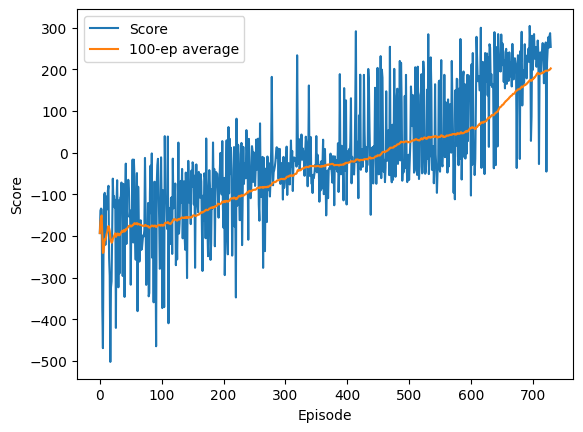

In [ ]:
import matplotlib.pyplot as plt
plt.plot(all_scores)
plt.plot([np.mean(all_scores[max(0, i-99):i+1]) for i in range(len(all_scores))])
plt.xlabel('Episode'); plt.ylabel('Score'); plt.legend(['Score', '100-ep average'])
plt.show()

Record and show a video

In [ ]:
def show_video_of_model(agent, filename='video.mp4'):
    env = make_env(render_mode='rgb_array')
    state, _ = env.reset()
    done = False
    frames = []
    while not done:
        frames.append(env.render())
        action = agent.act(state)
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
    env.close()
    imageio.mimsave(filename, frames, fps=30)

def show_video(filename='video.mp4'):
    if os.path.exists(filename):
        encoded = base64.b64encode(open(filename, 'rb').read()).decode('ascii')
        display(HTML(f'''<video autoplay loop controls style="height: 400px;">
            <source src="data:video/mp4;base64,{encoded}" type="video/mp4" /></video>'''))
    else:
        print("Could not find video")

show_video_of_model(agent)
show_video()

In [ ]:
def evaluate(agent, n_episodes=100):
    env = make_env()
    scores = []
    for _ in range(n_episodes):
        state, _ = env.reset()
        done, score = False, 0
        while not done:
            action = agent.act(state)
            state, reward, terminated, truncated, _ = env.step(action)
            score += reward
            done = terminated or truncated
        scores.append(score)
    scores = np.array(scores)
    print(f'Mean: {scores.mean():.1f} | Std: {scores.std():.1f}')
    print(f'Scored >= 200: {(scores >= 200).mean():.0%} | Crashed (< 0): {(scores < 0).mean():.0%}')
    return scores

scores = evaluate(agent)

Mean: 202.4 | Std: 75.5
Scored >= 200: 72% | Crashed (< 0): 5%


In [ ]:
for _ in range(8):
    env.reset()
    print(env.unwrapped.pad_center, round(env.unwrapped.pad_offset, 2))

3 -0.4
4 -0.2
5 0.0
8 0.6
4 -0.2
5 0.0
3 -0.4
4 -0.2


In [ ]:
torch.save(agent.local_qnetwork.state_dict(), 'checkpoint_random.pth')
from google.colab import files
files.download('checkpoint_random.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
for name in ['left', 'center', 'right']:
    my_lander.PAD_MODE = name
    fname = f'landing_{name}.mp4'
    show_video_of_model(agent, filename=fname)
    print('Saved', fname)

my_lander.PAD_MODE = 'random'   # put it back

Saved landing_left.mp4


Saved landing_center.mp4


Saved landing_right.mp4


In [ ]:
show_video('landing_left.mp4')

In [ ]:
show_video('landing_center.mp4')

In [ ]:
show_video('landing_right.mp4')

In [ ]:
from google.colab import files
for n in ['left', 'center', 'right']:
    files.download(f'landing_{n}.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for name in ['left', 'center', 'right', 'random']:
    my_lander.PAD_MODE = name
    print(name.upper())
    evaluate(agent)
my_lander.PAD_MODE = 'random'

LEFT
Mean: 213.5 | Std: 88.8
Scored >= 200: 81% | Crashed (< 0): 9%
CENTER
Mean: 213.3 | Std: 70.1
Scored >= 200: 74% | Crashed (< 0): 5%
RIGHT
Mean: 190.3 | Std: 95.2
Scored >= 200: 70% | Crashed (< 0): 8%
RANDOM
Mean: 208.4 | Std: 85.7
Scored >= 200: 73% | Crashed (< 0): 4%


In [ ]:
my_lander.PAD_MODE = 'right'
evaluate(agent, n_episodes=500)
my_lander.PAD_MODE = 'left'
evaluate(agent, n_episodes=500)
my_lander.PAD_MODE = 'random'

Mean: 201.7 | Std: 79.5
Scored >= 200: 72% | Crashed (< 0): 5%
Mean: 216.6 | Std: 80.4
Scored >= 200: 80% | Crashed (< 0): 5%


Double DQN agent

In [ ]:
class DoubleAgent(Agent):
    def learn(self, experiences, discount_factor):
        states, next_states, actions, rewards, dones = experiences
        # local network PICKS the best next action, target network EVALUATES it
        best_actions = self.local_qnetwork(next_states).detach().argmax(1, keepdim=True)
        next_q = self.target_qnetwork(next_states).detach().gather(1, best_actions)
        q_targets = rewards + discount_factor * next_q * (1 - dones)
        q_expected = self.local_qnetwork(states).gather(1, actions)
        loss = F.mse_loss(q_expected, q_targets)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.soft_update(self.local_qnetwork, self.target_qnetwork, interpolation_parameter)

agent_double = DoubleAgent(state_size, number_actions)

Training

In [ ]:
my_lander.PAD_MODE = 'random'
env = make_env()

epsilon = 1.0
scores_window = deque(maxlen=100)
double_scores = []

for episode in range(1, 3001):
    state, _ = env.reset()
    score, done = 0, False
    while not done:
        action = agent_double.act(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        agent_double.step(state, action, reward, next_state, terminated)
        state = next_state
        score += reward
        done = terminated or truncated
    scores_window.append(score)
    double_scores.append(score)
    epsilon = max(0.01, 0.995 * epsilon)
    avg = np.mean(scores_window)
    print(f'\rEpisode {episode}\tAverage Score: {avg:.2f}', end="")
    if episode % 100 == 0:
        print(f'\rEpisode {episode}\tAverage Score: {avg:.2f}')
    if avg >= 200.0:
        print(f'\nSolved in {episode - 100} episodes! Average Score: {avg:.2f}')
        break

torch.save(agent_double.local_qnetwork.state_dict(), 'checkpoint_double.pth')
from google.colab import files
files.download('checkpoint_double.pth')


Episode 100	Average Score: -195.46
Episode 200	Average Score: -110.39
Episode 300	Average Score: -40.56
Episode 400	Average Score: -22.27
Episode 500	Average Score: 21.96
Episode 600	Average Score: 85.58
Episode 700	Average Score: 184.52
Episode 723	Average Score: 200.07
Solved in 623 episodes! Average Score: 200.07


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for name, a in [('Original DQN', agent), ('Double DQN', agent_double)]:
    print(name)
    for mode in ['left', 'right']:
        my_lander.PAD_MODE = mode
        print(' ', mode)
        evaluate(a, n_episodes=500)
my_lander.PAD_MODE = 'random'

Original DQN
  left
Mean: 226.2 | Std: 68.9
Scored >= 200: 85% | Crashed (< 0): 4%
  right
Mean: 195.5 | Std: 84.9
Scored >= 200: 68% | Crashed (< 0): 6%
Double DQN
  left
Mean: 233.2 | Std: 48.4
Scored >= 200: 91% | Crashed (< 0): 0%
  right
Mean: 207.1 | Std: 85.1
Scored >= 200: 69% | Crashed (< 0): 5%


Setup and helper functions

In [ ]:
import os, time, shutil
import pandas as pd

SEEDS = [1, 2, 3]
VARIANTS = {'Original DQN': Agent, 'Double DQN': DoubleAgent}
MAX_EPISODES = 1500
EVAL_EPISODES = 500
os.makedirs('runs', exist_ok=True)
results = globals().get('results', {})   # survives re-running this cell

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def make_agent(cls, seed):
    set_seed(seed)
    a = cls(state_size, number_actions)
    # Network() resets torch's seed to 42 internally, so re-initialise weights with our seed
    torch.manual_seed(seed)
    for m in a.local_qnetwork.modules():
        if isinstance(m, nn.Linear):
            m.reset_parameters()
    a.target_qnetwork.load_state_dict(a.local_qnetwork.state_dict())
    return a

def train_one(a, seed):
    my_lander.PAD_MODE = 'random'
    train_env = make_env()
    epsilon, window = 1.0, deque(maxlen=100)
    for ep in range(1, MAX_EPISODES + 1):
        state, _ = train_env.reset(seed=seed) if ep == 1 else train_env.reset()
        score, done = 0, False
        while not done:
            action = a.act(state, epsilon)
            next_state, reward, terminated, truncated, _ = train_env.step(action)
            a.step(state, action, reward, next_state, terminated)
            state = next_state
            score += reward
            done = terminated or truncated
        window.append(score)
        epsilon = max(0.01, 0.995 * epsilon)
        if len(window) == 100 and np.mean(window) >= 200:
            return ep        # episode at which the 100-episode average reached 200
    return None              # not solved within MAX_EPISODES

def eval_quiet(a, mode, n):
    my_lander.PAD_MODE = mode
    eval_env = make_env()
    scores = []
    for _ in range(n):
        state, _ = eval_env.reset()
        score, done = 0, False
        while not done:
            state, reward, terminated, truncated, _ = eval_env.step(a.act(state))
            score += reward
            done = terminated or truncated
        scores.append(score)
    my_lander.PAD_MODE = 'random'
    return np.array(scores)

Run the experiment

In [ ]:
for seed in SEEDS:
    for name, cls in VARIANTS.items():
        if (name, seed) in results:
            continue                         # already done, so re-running resumes
        t0 = time.time()
        a_ = make_agent(cls, seed)
        solved_at = train_one(a_, seed)
        tag = name.split()[0].lower()
        torch.save(a_.local_qnetwork.state_dict(), f'runs/{tag}_seed{seed}.pth')
        s = eval_quiet(a_, 'random', EVAL_EPISODES)
        results[(name, seed)] = dict(solved_at=solved_at, mean=s.mean(), std=s.std(),
                                     good=(s >= 200).mean() * 100, crash=(s < 0).mean() * 100)
        pd.DataFrame([{'variant': k[0], 'seed': k[1], **v} for k, v in results.items()]
                     ).to_csv('runs/results.csv', index=False)
        print(f'{name} seed {seed}: solved at {solved_at} | eval mean {s.mean():.1f} '
              f'| good {results[(name, seed)]["good"]:.0f}% | crash {results[(name, seed)]["crash"]:.0f}% '
              f'| {(time.time() - t0) / 60:.1f} min')

Original DQN seed 1: solved at 747 | eval mean 215.8 | good 73% | crash 2% | 13.0 min
Double DQN seed 1: solved at 813 | eval mean 195.7 | good 60% | crash 4% | 11.7 min
Original DQN seed 2: solved at 1124 | eval mean 218.8 | good 80% | crash 5% | 18.2 min
Double DQN seed 2: solved at 808 | eval mean 222.8 | good 79% | crash 2% | 14.6 min
Original DQN seed 3: solved at 916 | eval mean 149.1 | good 45% | crash 15% | 14.8 min
Double DQN seed 3: solved at 825 | eval mean 200.9 | good 67% | crash 2% | 14.3 min


Summary table

In [ ]:
df = pd.DataFrame([{'variant': k[0], 'seed': k[1], **v} for k, v in results.items()])
print(df.round(1).to_string(index=False))
print()
print(df.groupby('variant')[['solved_at', 'mean', 'std', 'good', 'crash']].agg(['mean', 'std']).round(1))

     variant  seed  solved_at  mean   std  good  crash
Original DQN     1        747 215.8  61.3  73.4    1.6
  Double DQN     1        813 195.7  81.3  59.6    3.6
Original DQN     2       1124 218.8  75.4  80.2    4.6
  Double DQN     2        808 222.8  55.6  79.0    1.6
Original DQN     3        916 149.1 109.8  45.4   14.8
  Double DQN     3        825 200.9  73.5  67.0    2.2

             solved_at          mean         std        good       crash     
                  mean    std   mean   std  mean   std  mean   std  mean  std
variant                                                                      
Double DQN       815.3    8.7  206.4  14.4  70.1  13.2  68.5   9.8   2.5  1.0
Original DQN     929.0  188.8  194.6  39.4  82.2  24.9  66.3  18.4   7.0  6.9


Download everything as one zip


In [ ]:
shutil.make_archive('runs', 'zip', 'runs')
from google.colab import files
files.download('runs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>